<a href="https://colab.research.google.com/github/asnapareeth004-hue/encoder_decoder/blob/main/CBAM_ResNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install torch torchvision scikit-learn matplotlib seaborn

In [ ]:
# ==============================
# 1. Basic Python libraries
# ==============================
import os
import glob
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# 2. PyTorch libraries
# ==============================
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

# ==============================
# 3. Image processing
# ==============================
from PIL import Image

# ==============================
# 4. Scikit-learn
# ==============================
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ==============================
# 5. Progress bar
# ==============================
from tqdm import tqdm


print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

All libraries imported successfully!
PyTorch version: 2.14.1+cu130
GPU available: True


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [ ]:
class ChannelAttention(nn.Module):

    def __init__(self, channels, reduction=16):
        super().__init__()

        hidden = max(channels // reduction, 1)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.mlp(self.avg_pool(x))
        max_out = self.mlp(self.max_pool(x))

        attention = self.sigmoid(avg_out + max_out)

        return x * attention

In [ ]:
class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2, 1,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(x, dim=1, keepdim=True)

        max_out, _ = torch.max(x, dim=1, keepdim=True)

        combined = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        attention = self.sigmoid(self.conv(combined))

        return x * attention

In [ ]:
class CBAM(nn.Module):

    def __init__(self, channels, reduction=16):
        super().__init__()

        self.channel_attention = ChannelAttention(
            channels, reduction
        )

        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = self.channel_attention(x)

        x = self.spatial_attention(x)

        return x

In [ ]:
class ResNet18_CBAM(nn.Module):

    def __init__(self, num_classes=3):
        super().__init__()

        base = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        # Initial ResNet layers
        self.conv1 = base.conv1
        self.bn1 = base.bn1
        self.relu = base.relu
        self.maxpool = base.maxpool

        # ResNet stages
        self.layer1 = base.layer1
        self.layer2 = base.layer2
        self.layer3 = base.layer3
        self.layer4 = base.layer4

        # CBAM after each stage
        self.cbam1 = CBAM(64)
        self.cbam2 = CBAM(128)
        self.cbam3 = CBAM(256)
        self.cbam4 = CBAM(512)

        # Classification head
        self.avgpool = base.avgpool

        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.cbam1(x)

        x = self.layer2(x)
        x = self.cbam2(x)

        x = self.layer3(x)
        x = self.cbam3(x)

        x = self.layer4(x)
        x = self.cbam4(x)

        x = self.avgpool(x)

        x = torch.flatten(x, 1)

        x = self.fc(x)

        return x

In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/deep learning"

print(os.listdir(DATASET_PATH))

['PNEUMONIA', 'NORMAL', 'Covid']


In [ ]:
from pathlib import Path

classes = ["Covid", "NORMAL", "PNEUMONIA"]

for class_name in classes:

    folder = Path(DATASET_PATH) / class_name

    images = [
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    print(f"{class_name}: {len(images)} images")

Covid: 389 images
NORMAL: 135 images
PNEUMONIA: 292 images


In [ ]:
image_paths = []
labels = []

for class_name in classes:

    folder = Path(DATASET_PATH) / class_name

    for image in folder.iterdir():

        if image.is_file() and image.suffix.lower() in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:

            image_paths.append(str(image))
            labels.append(class_name)

print("Total images:", len(image_paths))

Total images: 816


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# First split: 70% training, 30% temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: 15% validation, 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 571
Validation: 122
Testing: 123


In [ ]:
OUTPUT_PATH = Path("/content/chest_xray")

# All the folder creation and shutil.copy2 code

In [ ]:
class ChestXrayDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):

        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

        self.class_to_idx = {
            "Covid": 0,
            "NORMAL": 1,
            "PNEUMONIA": 2
        }

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image = Image.open(
            self.image_paths[idx]
        ).convert("RGB")

        label_name = self.labels[idx].strip()

        label = self.class_to_idx[label_name]

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.Grayscale(num_output_channels=3),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.Grayscale(num_output_channels=3),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
train_data = ChestXrayDataset(
    X_train, y_train, train_transform
)

val_data = ChestXrayDataset(
    X_val, y_val, test_transform
)

test_data = ChestXrayDataset(
    X_test, y_test, test_transform
)

In [ ]:
train_loader = DataLoader(
    train_data,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_data,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_data,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

Image batch shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])
Labels: tensor([1, 0, 2, 2, 0, 0, 0, 0, 0, 2, 0, 1, 0, 0, 0, 1])


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = [
    train_data.class_to_idx[label]
    for label in train_data.labels
]

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=np.array(train_labels)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)

Class weights: tensor([0.6998, 2.0035, 0.9330], device='cuda:0')


In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

In [ ]:
model = ResNet18_CBAM(num_classes=3).to(device)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 211MB/s]

ResNet18_CBAM(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_runn

In [ ]:
images, labels = next(iter(train_loader))

images = images.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 3])


In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

In [ ]:
from tqdm import tqdm
import copy

num_epochs = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(num_epochs):

    # ---------------- TRAINING ----------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward propagation
        outputs = model(images)

        # 3. Calculate loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update model parameters
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    # Store metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_accuracy:.2f}%")

# Load best model
model.load_state_dict(best_model_weights)

print("\nTraining completed!")
print("Best Validation Loss:", best_val_loss)

100%|██████████| 36/36 [11:04<00:00, 18.45s/it]



Epoch [1/10]
Train Loss: 0.4022 | Train Accuracy: 86.34%
Val Loss: 0.1398 | Val Accuracy: 98.36%


100%|██████████| 36/36 [00:20<00:00,  1.79it/s]



Epoch [2/10]
Train Loss: 0.1337 | Train Accuracy: 95.97%
Val Loss: 0.1295 | Val Accuracy: 95.08%


100%|██████████| 36/36 [00:20<00:00,  1.75it/s]



Epoch [3/10]
Train Loss: 0.0604 | Train Accuracy: 98.42%
Val Loss: 0.1347 | Val Accuracy: 97.54%


... (10 outputs left out)

100%|██████████| 36/36 [00:21<00:00,  1.70it/s]



Epoch [9/10]
Train Loss: 0.0302 | Train Accuracy: 99.30%
Val Loss: 0.0501 | Val Accuracy: 99.18%


100%|██████████| 36/36 [00:21<00:00,  1.67it/s]



Epoch [10/10]
Train Loss: 0.0404 | Train Accuracy: 99.47%
Val Loss: 0.1368 | Val Accuracy: 96.72%

Training completed!
Best Validation Loss: 0.030759568555188962


In [ ]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Covid", "NORMAL", "PNEUMONIA"],
    digits=4
))

              precision    recall  f1-score   support

       Covid     1.0000    1.0000    1.0000        59
      NORMAL     0.9091    1.0000    0.9524        20
   PNEUMONIA     1.0000    0.9545    0.9767        44

    accuracy                         0.9837       123
   macro avg     0.9697    0.9848    0.9764       123
weighted avg     0.9852    0.9837    0.9839       123



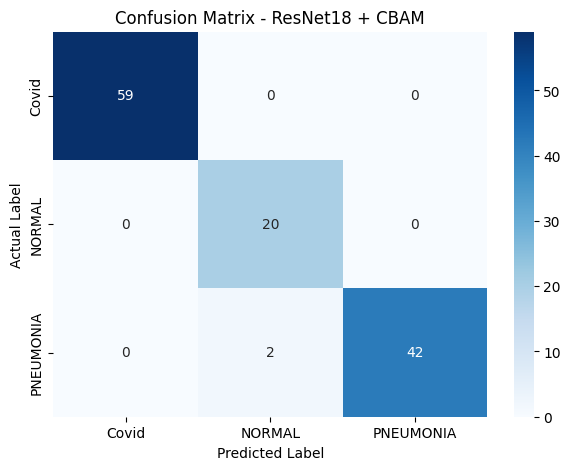

In [ ]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Covid", "NORMAL", "PNEUMONIA"],
    yticklabels=["Covid", "NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - ResNet18 + CBAM")
plt.show()